# Lab01 - sprint 1 (доп. для КТвД). Растворимость и молекулярная масса

## Содержание

**[Random Variables: Растворимость и молекулярная масса](#sec-1)**

- [1. Description. Почему L и M — случайные величины](#sec-1-1)
  - [1.1. Закон больших чисел](#lln)
  - [1.2. Центральная предельная теорема](#clt)
  - [1.3. Теорема Гливенко — Кантелли](#gk)
- [2. Independence. Связаны ли L и M](#sec-1-2)
- [3. EDA. Как выглядят данные](#sec-1-3)
- [4. Resume. Итог](#sec-1-4)


<a id="sec-1"></a>
## Random Variables: Растворимость и молекулярная масса

Работа будет проходить с очищенной выборкой DrugBank (`cleaned_data.csv`). После просмотра датасета были выбранны следующие две характеристики:

- **L** (`cal_logs`) — логарифм расчётной растворимости в воде (logS);
- **M** (`cal_molecular_weight`) — расчётная молекулярная масса.

Задание (чуть отличается от инфохимиков):

1. Доказать, что **L** и **M** — **случайные величины**.
2. Проверить **независимость / зависимость** пары.
3. Выполнить **EDA**.

Ниже — выполнение пунктов в соответствии с планом из (`data_review.ipynb`).


In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "supporting_functions" / "datacleaner.py").is_file()
)

sys.path.insert(0, str(project_root))

from supporting_functions.data_structure import plot_corr_matrix

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

RNG = np.random.default_rng(42)

df = pd.read_csv(project_root / "cleaned_data.csv")
pair = df[["cal_logs", "cal_molecular_weight"]].dropna()
l = pair["cal_logs"].to_numpy()
m = pair["cal_molecular_weight"].to_numpy()
N = len(l)

print(f"Молекул с L и M: {N}, пропусков в паре нет")

Молекул с L и M: 10046, пропусков в паре нет




<a id="sec-1-1"></a>

### 1. Description. Почему L и M — случайные величины

Допустим будем брать случайную молекулу из базы. У неё есть logS и масса, и нам заранее для конкретной будущей молекулы точные числа будут неизвестны: одна молекула легче расстворима, другая тяжелее. Поэтому можно судить, что **L** и **M** — случайные величины на одной генеральной совокупности молекул.

Ниже — графики, на которых видно, что при случайном выборе молекулы, ее данные заранее нельзя указать точно.


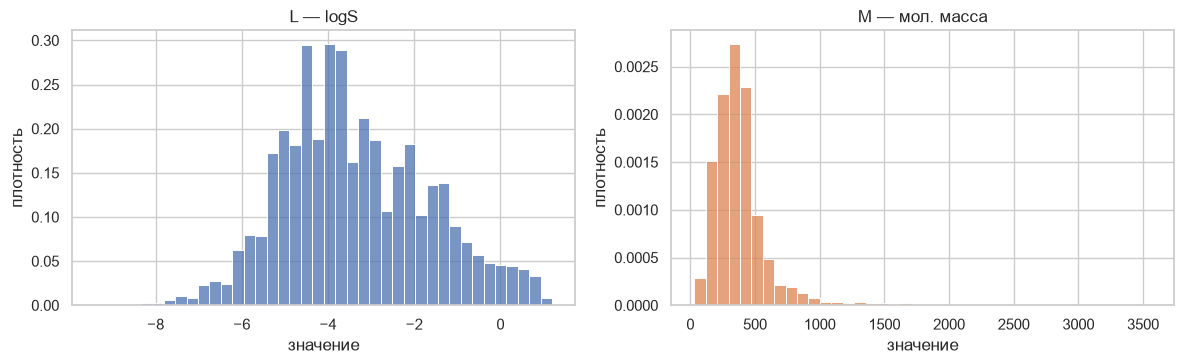

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, x, name, color in zip(axes, (l, m), ("L — logS", "M — мол. масса"), ("C0", "C1")):
    sns.histplot(x=x, bins=40, stat="density", color=color, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("значение")
    ax.set_ylabel("плотность")
plt.tight_layout()


<div class="notebook-takeaway">

**Вывод:** обе величины разбросаны по широким диапазонам, то есть типичная молекула не «зафиксирована» каким-то одним числом, а значит — это случайные величины, и нам их удобно будет описывать вероятностно.

</div>




<a id="lln"></a>

#### 1.1. Закон больших чисел

**Ожидаем:** при случайном отборе молекул с возвращением накопленное среднее с ростом $n$ приближается к среднему по всей базе (линия пунктиром).

На графике ниже — первые $2000$ шагов накопленного среднего (этого хватает, чтобы увидить ожидаемое сужение, но при этом видеть разброс и выбросы в начале).


величина,L,M
n,,
50,0.192,26.900
200,0.097,13.210
1000,0.043,5.996
2000,0.030,4.010


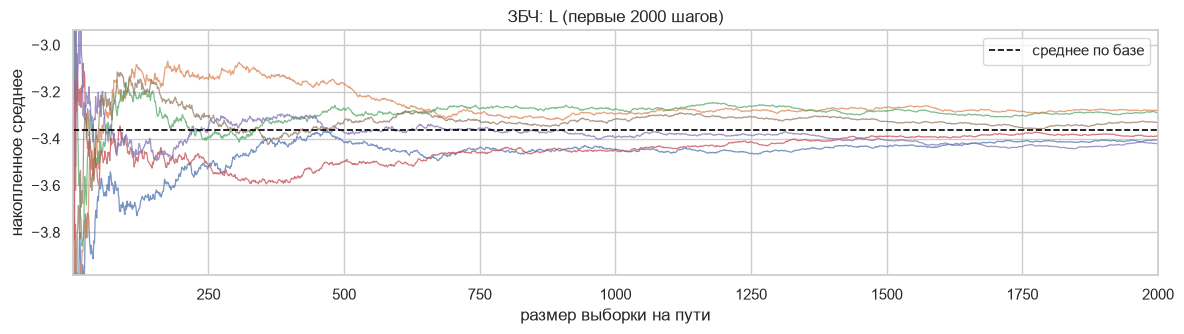

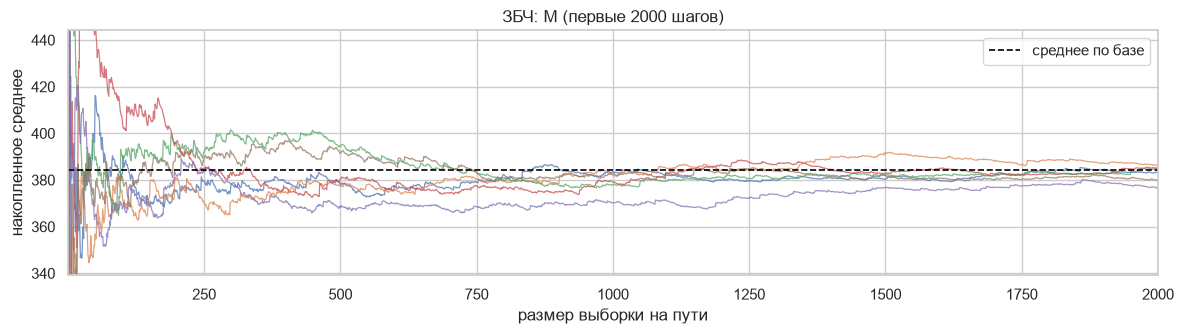

In [3]:
def lln_demo(x, label, true_mean, n_path=5000, n_show=6, xmax=2000):
    fig, ax = plt.subplots(figsize=(12, 3.5))
    x_axis = np.arange(1, n_path + 1)
    path_vals = []

    for _ in range(n_show):
        idx = RNG.integers(0, N, size=n_path)
        sample = x[idx]
        running = np.cumsum(sample) / x_axis
        ax.plot(x_axis[:xmax], running[:xmax], lw=0.9, alpha=0.75)
        path_vals.append(running[:xmax])

    ax.axhline(true_mean, color="black", ls="--", lw=1.2, label="среднее по базе")
    all_y = np.concatenate(path_vals)
    y_lo, y_hi = np.percentile(all_y, [0.5, 99.5])
    pad = max((y_hi - y_lo) * 0.22, abs(true_mean) * 0.04 + 1e-6)
    ax.set_xlim(1, xmax)
    ax.set_ylim(y_lo - pad, y_hi + pad)
    ax.set_title(f"ЗБЧ: {label} (первые {xmax} шагов)")
    ax.set_xlabel("размер выборки на пути")
    ax.set_ylabel("накопленное среднее")
    ax.legend(loc="upper right")
    plt.tight_layout()
    return fig

lln_demo(l, "L", l.mean(), xmax=2000)
lln_demo(m, "M", m.mean(), xmax=2000)

lln_rows = []
for name, x in (("L", l), ("M", m)):
    for n in (50, 200, 1000, 2000):
        errors = []

        for _ in range(1000):
            s = x[RNG.integers(0, N, size=n)]
            errors.append(abs(s.mean() - x.mean()))

        lln_rows.append({"величина": name, "n": n, "средняя ошибка среднего": np.mean(errors)})
pd.DataFrame(lln_rows).pivot(index="n", columns="величина", values="средняя ошибка среднего").round(3)

<div class="notebook-takeaway">

**Получили:** при случайном отборе с возвращением накопленные средние сначала сильно колеблются при малых $n$, затем сходятся к пунктирной линии (среднее по базе). Для **L** стабилизация $\approx -3.36$; для **M** $\approx 385$. Имеются редкие ранние выбросы на обоих графиках, но уже на первых сотнях шагов среднее близко к базе и графики начинают сужаться к среднему (но все еще не сливаются в одну линию и даже чуть-чуть колеблются - особенно видно у **M**). Выше графкиов в таблице средняя ошибка убывает при росте $n$ — это согласуется с ЗБЧ.

</div>




<a id="clt"></a>

#### 1.2. Центральная предельная теорема

**Ожидаем:** если много раз взять выборку из $n$ молекул с возвращением и каждый раз посчитать среднее **L** или **M**, то при росте $n$ такие средние должны **скучковаться** около обычного среднего по всей базе, а форма «разрозненных» значений должна стать похожей на **колокол** (нормальное), а не как у исходных данных по молекулам.

Ниже — графики для $n = 5$, $20$, $100$. В таблице смотрим, насколько столбец **std(средних)** близок к **теор. std** (расчётный разброс при таком $n$).


std(средних)  теор. std
величина n                           
L        5           0.770      0.765
         20          0.397      0.382
         100         0.174      0.171
M        5         101.920    106.045
         20         52.489     53.023
         100        24.199     23.712

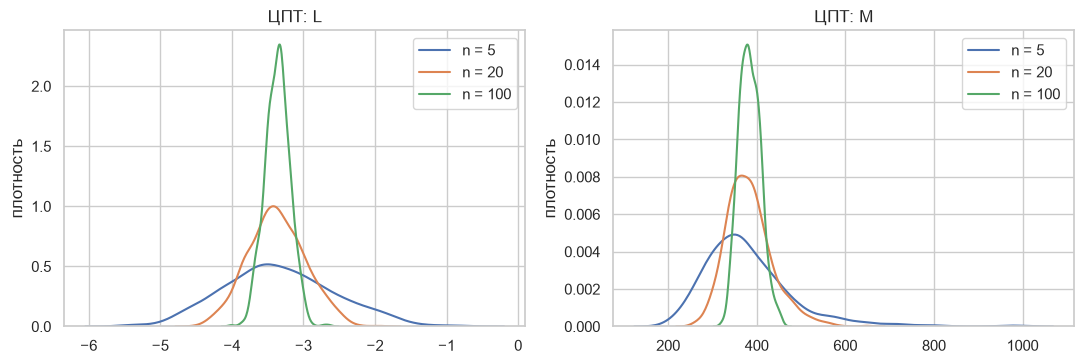

In [4]:
clt_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

for ax, (name, x) in zip(axes, (("L", l), ("M", m))):
    for n in (5, 20, 100):
        means = np.array([x[RNG.integers(0, N, size=n)].mean() for _ in range(800)])
        sns.kdeplot(means, ax=ax, label=f"n = {n}")
        clt_rows.append({
            "величина": name,
            "n": n,
            "std(средних)": means.std(),
            "теор. std": x.std(ddof=1) / np.sqrt(n),
        })

    ax.set_title(f"ЦПТ: {name}")
    ax.set_ylabel("плотность")
    ax.legend()
    
plt.tight_layout()
pd.DataFrame(clt_rows).set_index(["величина", "n"]).round(3)

<div class="notebook-takeaway">

**Получили:** при $n = 5$ кривые **широкие** — среднее по пяти молекулам может сильно отличаться от базы; при $n = 100$ получился **горб** — это намного уже, и центр ближе к среднему по базе (**L** около $-3{,}36$, **M** около $385$). Уже видна форма колокола, но при малых $n$ ещё бывают хвосты и перекос. В таблице выше **std(средних)** почти совпадает с **теор. std** и для **L**, и для **M** — с ЦПТ это сходится.

</div>




<a id="gk"></a>

#### 1.3. Теорема Гливенко — Кантелли

**Ожидаем:** если взять выборку из $n$ молекул, то ступенчатая кривая «доля молекул с значением не больше $x$» по выборке должна всё лучше совпадать с такой же кривой по всей базе (чёрная линия), когда $n$ растёт.

Ниже — сравнение для $n = 50$ и $200$. В таблице столбец **средн. sup|F_n-F|** — насколько в среднем колеблется выборочная кривая относительно кривой по базе (чем меньше, тем ближе).


,величина,n,средн. sup|F_n-F|
0,L,50,0.1193
1,L,200,0.0699
2,M,50,0.1154
3,M,200,0.0551


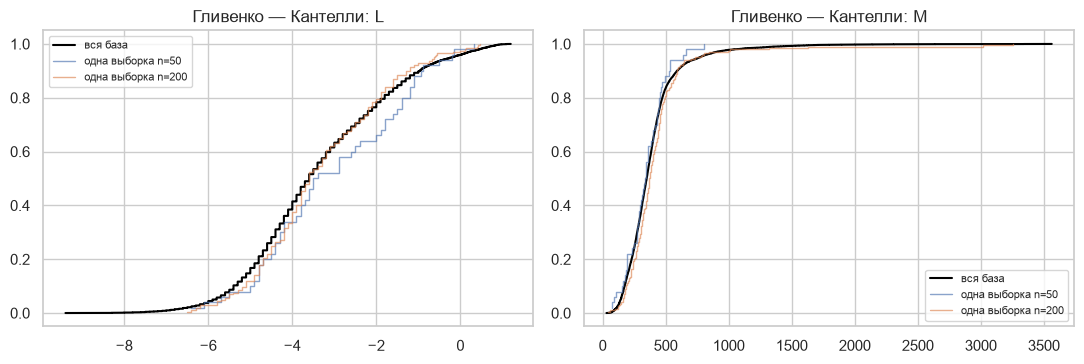

In [5]:
def ecdf(values):
    sorted_x = np.sort(values)
    y = np.arange(1, len(sorted_x) + 1) / len(sorted_x)

    return sorted_x, y

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
gk_rows = []

for ax, (name, x) in zip(axes, (("L", l), ("M", m))):
    full_x, full_y = ecdf(x)
    ax.step(full_x, full_y, where="post", color="black", lw=1.5, label="вся база")

    for n in (50, 200):
        trials = []

        for _ in range(100):
            samp = x[RNG.integers(0, N, size=n)]
            sx, sy = ecdf(samp)
            interp = np.interp(full_x, sx, sy, left=0, right=1)
            trials.append(np.max(np.abs(interp - full_y)))

        gk_rows.append({"величина": name, "n": n, "средн. sup|F_n-F|": np.mean(trials)})
        sx, sy = ecdf(x[RNG.integers(0, N, size=n)])
        ax.step(sx, sy, where="post", lw=1.0, alpha=0.65, label=f"одна выборка n={n}")

    ax.set_title(f"Гливенко — Кантелли: {name}")
    ax.legend(fontsize=8)
    
plt.tight_layout()
pd.DataFrame(gk_rows).round(4)

<div class="notebook-takeaway">

**Получили:** цветные ступеньки при $n = 50$ заметнее отходят от чёрной, при $n = 200$ уже ближе к ней — и для **L**, и для **M**. В таблице **средн. sup|F_n-F|** при переходе с 50 на 200 падает (у **L** примерно с $0{,}12$ до $0{,}07$, у **M** с $0{,}11$ до $0{,}06$). Выборочное распределение приближается к распределению по базе — это согласуется с теоремой Гливенко — Кантелли.

</div>


**Итоговый вывод:**

Так как все три теоремы выполненны, то и наши признаки (logS и мол. масса) — это случаные величины.




<a id="sec-1-2"></a>

### 2. Independence. Связаны ли L и M

LogS и масса — разные свойства одной молекулы. Нам нужно установить, **независимы ли** столбцы при случайном выборе строки (или описать **зависимость**).

**Ожидаем:** если связи нет, на графике облако (пятно точек, где точка — молекула) **размазано кругом** — нет явного наклона, и в таблице Пирсон и Спирмен **около нуля** (порядка $\pm 0{,}05$–$0{,}1$), p-value не крошечные. Если связь есть, точки тянутся **вдоль линии** (здесь ожидаем: чем **больше M**, тем **ниже L**), коэффициенты **заметно уходят от нуля** (по модулю хотя бы $\approx 0{,}3$–$0{,}4$ и больше), p-value малы.

Проверяем гипотезу «связи нет» ($H_0$) против «связь есть» ($H_1$). Ниже — таблица (Пирсон — насколько близки к прямой; Спирмен — та же идея для монотонной связи) и график «logS против массы», где **прямая** — усреднённый наклон по всей базе.


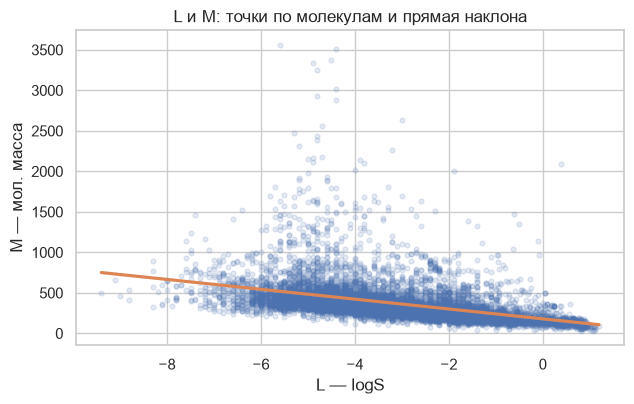

In [6]:
pearson = stats.pearsonr(l, m)
spearman = stats.spearmanr(l, m)
core = (l > np.percentile(l, 1)) & (l < np.percentile(l, 99))
core &= (m > np.percentile(m, 1)) & (m < np.percentile(m, 99))
pearson_core = stats.pearsonr(l[core], m[core])

def p_str(p):
    return "< 1e-300" if p == 0 else (f"{p:.2e}" if p < 1e-4 else f"{p:.4f}")

corr_rows = [
    {"коэффициент": "Пирсон (все данные)", "значение": pearson.statistic, "p-value": p_str(pearson.pvalue)},
    {"коэффициент": "Пирсон (без крайних 1%)", "значение": pearson_core.statistic, "p-value": p_str(pearson_core.pvalue)},
    {"коэффициент": "Спирмен", "значение": spearman.statistic, "p-value": p_str(spearman.pvalue)},
]
pd.DataFrame(corr_rows).set_index("коэффициент").round({"значение": 3})

plt.figure(figsize=(6.5, 4.2))
sns.regplot(x=l, y=m, scatter_kws={"alpha": 0.15, "s": 12}, line_kws={"color": "C1"})
plt.xlabel("L — logS")
plt.ylabel("M — мол. масса")
plt.title("L и M: точки по молекулам и прямая наклона")
plt.tight_layout()

<div class="notebook-takeaway">

**Получили:** на графике точки уходят **вниз вправо** — у более тяжёлых молекул logS в среднем **ниже**, прямая это подтверждает. В таблице Пирсон около $-0{,}44$ (если убрать крайние 1% — около $-0{,}49$), Спирмен около $-0{,}63$; p-value практически нулевые. Это далеко от «ноль и нет связи», поэтому **L** и **M** лучше считать **связанными**, а не независимыми.

</div>




<a id="sec-1-3"></a>

### 3. EDA. Как выглядят данные

Описательные статистики, форма распределений, связь **L** и **M**. 


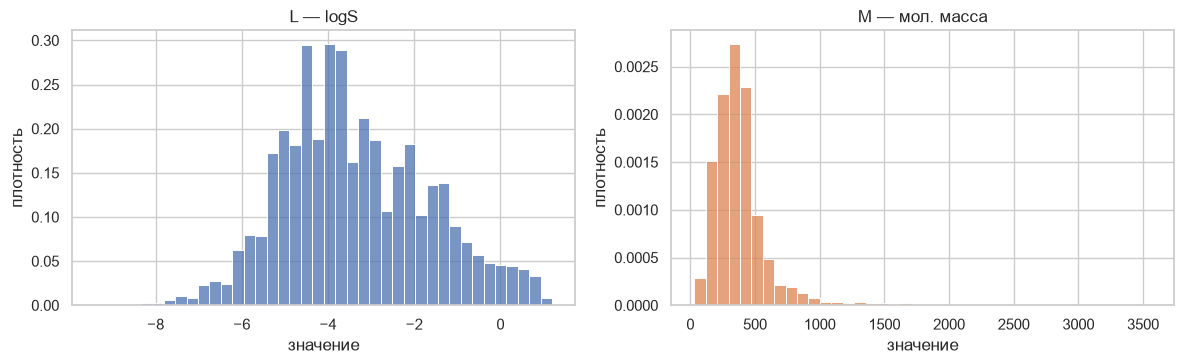

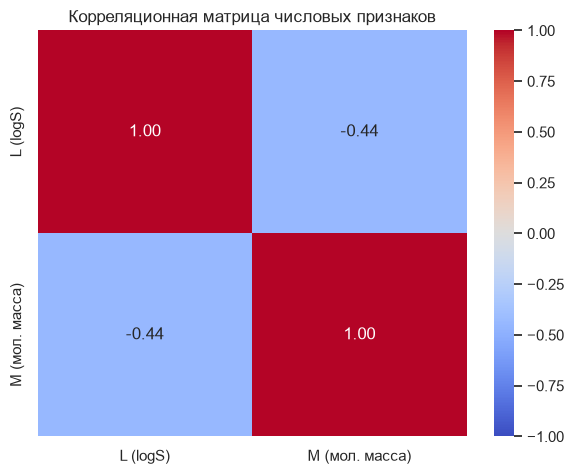

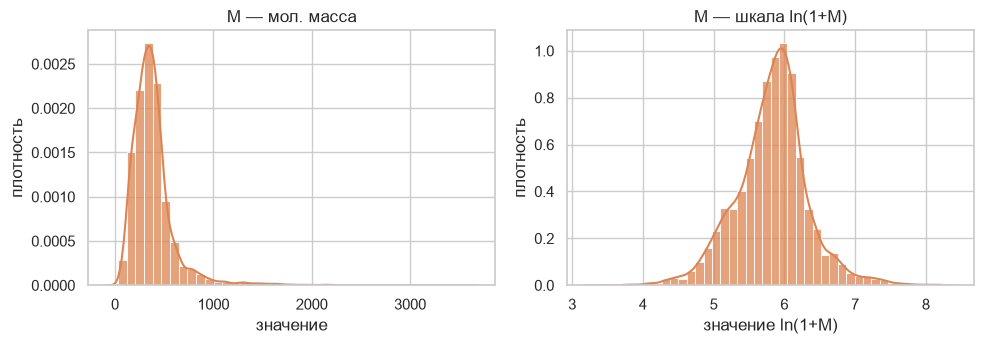

In [7]:
eda = df[["cal_logs", "cal_molecular_weight"]].dropna()
summary = eda.describe().T
summary["skew"] = eda.skew()
summary["kurtosis"] = eda.kurtosis()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, x, name, color in zip(
    axes,
    (eda["cal_logs"], eda["cal_molecular_weight"]),
    ("L — logS", "M — мол. масса"),
    ("C0", "C1"),
):
    sns.histplot(x=x, bins=40, stat="density", color=color, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("значение")
    ax.set_ylabel("плотность")
plt.tight_layout()
plt.show()
summary.round(3)

eda_ru = eda.rename(
    columns={"cal_logs": "L (logS)", "cal_molecular_weight": "M (мол. масса)"}
)
plot_corr_matrix(eda_ru)
plt.show()

m_log = np.log1p(m)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
sns.histplot(m, bins=40, stat="density", color="C1", ax=ax[0])
sns.kdeplot(m, color="C1", linewidth=1.5, ax=ax[0])
ax[0].set_title("M — мол. масса")
ax[0].set_xlabel("значение")
ax[0].set_ylabel("плотность")
sns.histplot(m_log, bins=40, stat="density", color="C1", ax=ax[1])
sns.kdeplot(m_log, color="C1", linewidth=1.5, ax=ax[1])
ax[1].set_title("M — шкала ln(1+M)")
ax[1].set_xlabel("значение ln(1+M)")
ax[1].set_ylabel("плотность")
plt.tight_layout()

<div class="notebook-takeaway">

**Гистограммы и таблица:** те же **L** и **M**, что в начале.

**Второй рисунок:** тепловая карта корреляций. В ячейке **L**×**M** стоит коэффициент корреляции Пирсона: одно число от **$-1$** до **$+1$**, которое говорит, насколько два признака «тянутся» вдоль прямой. **$0$** — линейной связи почти нет; **минус** — когда одно растёт, другое в среднем падает; **плюс** — оба растут вместе. **Вывод:** **L** и **M** связаны линейно и отрицательно (как на графике в пункте 2), а не как два независимых столбца.

**Последний рисунок:** две гистограммы одних и тех же молекул. Левая — **M** до преобразований. Правая — пересчитанная по формуле **ln(1+M)**. У левой основная масса молекул слева на оси, редкие тяжёлые тянут хвост вправо; у правой график как-бы растянулся в обе стороны — редкие тяжёлые молекулы стали ближе к основной куче на шкале. **Вывод:** форма распределения массы неудобна в исходных единицах; log-подобная ось — тот же набор значений, только проще увидеть, куда сгруппированы молекулы.

</div>




<a id="sec-1-4"></a>

### 4. Resume. Итог

**Данные.** $10046$ молекул, в паре **L** / **M** пропусков нет.

**1. Случайные величины и предельные теоремы.** По начальным гистограммам **L** и **M** размазаны по широким диапазонам — каждую молекулу описали случайными величинами. **ЗБЧ:** накопленное среднее при отборе с возвращением сходится к среднему по базе, табличная ошибка падает при росте $n$. **ЦПТ:** распределения средних по $n$ молекул сжимается к колоколу вокруг тех же центров, при $n=100$ форма уже узкая, эмпирический разброс средних близок к теоретическому. **Гливенко — Кантелли:** ступенчатая эмпирическая функция распределения при $n=200$ ближе к «базовой» чёрной кривой, чем при $n=50$. По полученным результатам мы можешь заявлять, что эти признаки — случайные велечины.

**2. Независимость L и M.** На графике точек прямая наклоненна **вниз вправо**; Пирсон и Спирмен **отрицательные**, p-value практически нули. **L** и **M** друг от друга **зависят**: у более тяжёлых молекул в среднем **ниже** logS.

**3. EDA.** Гистограммы: **M** с длинным правым хвостом (много лёгких, мало очень тяжёлых), **L** — в основном один горб без такого хвоста. Корреляционная матрица — та же история, что и во втором пункте: ячейка **L**×**M** отрицательная, не около нуля. Сравнение **M** и **ln(1+M)** на одних молекулах показало следующее: на исходной оси хвост тянет график вправо, после ln-пересчёта редкие тяжёлые молекулы ближе к основной куче — данные те же, но становится нагляднее форма распределения массы.
